Prototipo 1

https://www.kaggle.com/datasets/theabah0/openorclosedeyes/data

In [14]:
import os
import math
import shutil
import urllib.request
import cv2
import numpy as np
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

# 1. Descargar modelo de MediaPipe si no está en la carpeta
MODELO_MP = "face_landmarker.task"
if not os.path.exists(MODELO_MP):
    print("Descargando face_landmarker.task...")
    url = "https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task"
    urllib.request.urlretrieve(url, MODELO_MP)

# 2. Inicializar detector de landmarks
base_options = python.BaseOptions(model_asset_path=MODELO_MP)
options = vision.FaceLandmarkerOptions(
    base_options=base_options,
    num_faces=1,
    min_face_detection_confidence=0.4
)
detector = vision.FaceLandmarker.create_from_options(options)

ANCHO_ROI, ALTO_ROI = 64, 24

def extraer_roi_ocular(frame_bgr):
    h, w, _ = frame_bgr.shape
    rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
    resultado = detector.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb))

    if not resultado.face_landmarks:
        return None

    lm = resultado.face_landmarks[0]

    # Centros de ojo izquierdo y derecho
    ojo_izq = np.array([(lm[33].x + lm[133].x) * 0.5 * w, (lm[33].y + lm[133].y) * 0.5 * h])
    ojo_der = np.array([(lm[362].x + lm[263].x) * 0.5 * w, (lm[362].y + lm[263].y) * 0.5 * h])

    # Rotar imagen para alinear ambos ojos horizontalmente
    angulo = math.degrees(math.atan2(ojo_der[1] - ojo_izq[1], ojo_der[0] - ojo_izq[0]))
    centro_ojos = ((ojo_izq[0] + ojo_der[0]) * 0.5, (ojo_izq[1] + ojo_der[1]) * 0.5)
    M = cv2.getRotationMatrix2D(centro_ojos, angulo, 1.0)
    rotada = cv2.warpAffine(frame_bgr, M, (w, h), flags=cv2.INTER_CUBIC)

    # Recortar franja binocular proporcional a la distancia entre ojos
    dist_ojos = np.linalg.norm(ojo_der - ojo_izq)
    if dist_ojos < 15:
        return None

    mitad_w = int(dist_ojos * 0.95)
    mitad_h = int(mitad_w * (ALTO_ROI / ANCHO_ROI))

    cx, cy = int(centro_ojos[0]), int(centro_ojos[1])
    recorte = rotada[max(0, cy - mitad_h):min(h, cy + mitad_h), max(0, cx - mitad_w):min(w, cx + mitad_w)]
    if recorte.size == 0:
        return None

    gris = cv2.cvtColor(recorte, cv2.COLOR_BGR2GRAY)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(4, 4))
    return clahe.apply(cv2.resize(gris, (ANCHO_ROI, ALTO_ROI)))

# 3. Limpiar destino anterior y procesar todas las imágenes de ambas carpetas
CARPETA_ORIGEN = r"C:\Users\Nico\Desktop\Dasaset ojos"
CARPETA_DESTINO = r"C:\Users\Nico\Desktop\Dataset_Ojos_ROI"

if os.path.exists(CARPETA_DESTINO):
    shutil.rmtree(CARPETA_DESTINO)

for clase in ["ClosedFace", "OpenFace"]:
    ruta_in = os.path.join(CARPETA_ORIGEN, clase)
    ruta_out = os.path.join(CARPETA_DESTINO, clase)
    os.makedirs(ruta_out, exist_ok=True)

    guardadas = 0
    for archivo in os.listdir(ruta_in):
        img = cv2.imread(os.path.join(ruta_in, archivo))
        if img is None:
            continue
        roi = extraer_roi_ocular(img)
        if roi is not None:
            cv2.imwrite(os.path.join(ruta_out, f"roi_{guardadas:04d}.png"), roi)
            guardadas += 1

    print(f"Clase '{clase}': {guardadas} recortes válidos guardados.")

Clase 'ClosedFace': 1176 recortes válidos guardados.
Clase 'OpenFace': 1230 recortes válidos guardados.


Cargando 1176 imágenes de 'ClosedFace'...
Cargando 1230 imágenes de 'OpenFace'...

Informe de clasificación:
               precision    recall  f1-score   support

Ojos Cerrados       0.95      0.95      0.95      1176
Ojos Abiertos       0.95      0.96      0.95      1230

     accuracy                           0.95      2406
    macro avg       0.95      0.95      0.95      2406
 weighted avg       0.95      0.95      0.95      2406



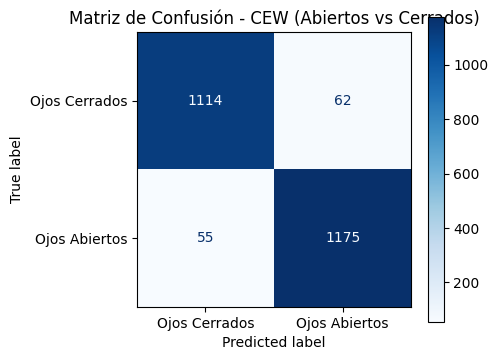

Modelo guardado correctamente en 'modelo_atencion.pkl'


In [15]:
import os
import cv2
import joblib
import numpy as np
import matplotlib.pyplot as plt
from skimage.feature import hog, local_binary_pattern
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

DATASET_DIR = r"C:\Users\Nico\Desktop\Dataset_Ojos_ROI"
CLASES = ["ClosedFace", "OpenFace"]

def extraer_caracteristicas(img_gray):
    feat_hog = hog(
        img_gray, orientations=9, pixels_per_cell=(8, 8),
        cells_per_block=(2, 2), feature_vector=True
    )
    lbp = local_binary_pattern(img_gray, P=8, R=1, method="uniform")
    h, w = lbp.shape
    hist_lbp = []
    for r in range(2):
        for c in range(4):
            celda = lbp[r*(h//2):(r+1)*(h//2), c*(w//4):(c+1)*(w//4)]
            hist, _ = np.histogram(celda.ravel(), bins=np.arange(0, 11), density=True)
            hist_lbp.extend(hist)
    return np.concatenate([feat_hog, np.array(hist_lbp)])

X, y = [], []
for idx, clase in enumerate(CLASES):
    carpeta = os.path.join(DATASET_DIR, clase)
    archivos = sorted(os.listdir(carpeta))
    print(f"Cargando {len(archivos)} imágenes de '{clase}'...")
    for f in archivos:
        img = cv2.imread(os.path.join(carpeta, f), cv2.IMREAD_GRAYSCALE)
        if img is not None:
            X.append(extraer_caracteristicas(img))
            y.append(idx)

X = np.array(X, dtype=np.float32)
y = np.array(y)

# Validación cruzada (5 particiones en paralelo)
modelo = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, probability=True))
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
y_pred = cross_val_predict(modelo, X, y, cv=skf, n_jobs=-1)

print("\nInforme de clasificación:")
print(classification_report(y, y_pred, target_names=["Ojos Cerrados", "Ojos Abiertos"]))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y, y_pred, display_labels=["Ojos Cerrados", "Ojos Abiertos"], cmap="Blues", ax=ax
)
plt.title("Matriz de Confusión - CEW (Abiertos vs Cerrados)")
plt.tight_layout()
plt.show()

# Entrenar con todas las muestras y guardar el modelo final
modelo.fit(X, y)
joblib.dump({"modelo": modelo, "clases": CLASES}, "modelo_atencion.pkl")
print("Modelo guardado correctamente en 'modelo_atencion.pkl'")

In [19]:
import math
import cv2
import joblib
import numpy as np
from collections import deque

# Cargar tu imagen local conservando el canal alfa (transparencia)
img_dormido = cv2.imread("durmiendo.png", cv2.IMREAD_UNCHANGED)
if img_dormido is None:
    print("Aviso: No se encontró 'durmiendo.png' en la carpeta del cuaderno.")

def superponer_png(fondo, png, x, y, tam=115):
    """Superpone un PNG (con o sin transparencia) sobre el fotograma en (x, y)."""
    if png is None:
        return
    icono = cv2.resize(png, (tam, tam), interpolation=cv2.INTER_AREA)
    h_f, w_f, _ = fondo.shape

    if x < 0 or y < 0 or x + tam > w_f or y + tam > h_f:
        return

    if icono.shape[2] == 4:
        alpha = icono[:, :, 3] / 255.0
        for c in range(3):
            fondo[y:y+tam, x:x+tam, c] = (
                alpha * icono[:, :, c] + (1 - alpha) * fondo[y:y+tam, x:x+tam, c]
            )
    else:
        fondo[y:y+tam, x:x+tam] = icono[:, :, :3]

# Cargar modelo entrenado
paquete = joblib.load("modelo_atencion.pkl")
modelo = paquete["modelo"]
CLASES = paquete["clases"]  # ['ClosedFace', 'OpenFace']

cap = cv2.VideoCapture(1)
historial = deque(maxlen=5)
contador_frame = 0

print("Cámara iniciada. Pulsa ESC en la ventana del vídeo para salir.")

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break
    frame = cv2.flip(frame, 1)
    contador_frame += 1
    h, w, _ = frame.shape

    roi = extraer_roi_ocular(frame)
    estado = "sin_rostro"

    if roi is not None:
        feat = extraer_caracteristicas(roi).reshape(1, -1)
        probs = modelo.predict_proba(feat)[0]  # [ClosedFace, OpenFace]
        pred_idx = 0 if probs[0] > 0.65 else 1
        historial.append(pred_idx)

        ganador = max(set(historial), key=historial.count)
        estado = CLASES[ganador]

    # Franja superior oscura
    cv2.rectangle(frame, (0, 0), (w, 48), (20, 20, 20), -1)

    if estado == "OpenFace":
        color = (0, 230, 0)
        cv2.rectangle(frame, (0, 0), (w, h), color, 8)
        cv2.putText(frame, "OJOS ABIERTOS - DESPIERTO", (18, 32),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.78, color, 2, cv2.LINE_AA)

    elif estado == "ClosedFace":
        # Tinte nocturno azulado suave al cerrar los ojos
        overlay = frame.copy()
        cv2.rectangle(overlay, (0, 48), (w, h), (140, 50, 10), -1)
        frame = cv2.addWeighted(overlay, 0.25, frame, 0.75, 0)

        color = (255, 170, 40)
        cv2.rectangle(frame, (0, 0), (w, h), color, 10)
        cv2.putText(frame, "OJOS CERRADOS - DURMIENDO... Zzz", (18, 32),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.78, color, 2, cv2.LINE_AA)

        # Superponer tu imagen 'durmiendo.png' con movimiento suave
        rebote_y = int(6 * math.sin(contador_frame * 0.15))
        superponer_png(frame, img_dormido, 25, 70 + rebote_y, tam=115)

    cv2.imshow("Prototipo 1 - Control Ocular", frame)
    if cv2.waitKey(1) & 0xFF == 27:
        break

cap.release()
cv2.destroyAllWindows()

Cámara iniciada. Pulsa ESC en la ventana del vídeo para salir.


Prototipo 2

In [3]:
import os
import urllib.request
import threading
import time
import math
import ctypes
import cv2
import numpy as np
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
from deepface import DeepFace

# --- 1. MOTOR DE AUDIO MIDI NATIVO DE WINDOWS ---
class WindowsMidiSynth:
    def __init__(self):
        self.winmm = ctypes.windll.winmm
        self.hmidi = ctypes.c_void_p()
        self.winmm.midiOutOpen(ctypes.byref(self.hmidi), 0, 0, 0, 0)
        self.current_note = None
        self.current_program = -1

    def set_instrument(self, program):
        if program != self.current_program:
            self.current_program = program
            self.winmm.midiOutShortMsg(self.hmidi, 0xC0 | (program << 8))

    def play_note(self, note, velocity=100):
        if note != self.current_note:
            self.stop_note()
            self.current_note = note
            self.winmm.midiOutShortMsg(self.hmidi, 0x90 | (note << 8) | (velocity << 16))

    def stop_note(self):
        if self.current_note is not None:
            self.winmm.midiOutShortMsg(self.hmidi, 0x80 | (self.current_note << 8))
            self.current_note = None

    def play_percussion(self, drum_note=49, velocity=115):
        self.winmm.midiOutShortMsg(self.hmidi, 0x99 | (drum_note << 8) | (velocity << 16))

    def close(self):
        self.stop_note()
        self.winmm.midiOutClose(self.hmidi)

# --- 2. MEDIAPIPE FACE LANDMARKER ---
MODEL_PATH = "face_landmarker.task"
if not os.path.exists(MODEL_PATH):
    url = "https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task"
    urllib.request.urlretrieve(url, MODEL_PATH)

base_options = python.BaseOptions(model_asset_path=MODEL_PATH)
options = vision.FaceLandmarkerOptions(
    base_options=base_options,
    running_mode=vision.RunningMode.VIDEO,
    num_faces=1,
    min_face_detection_confidence=0.6,
    min_tracking_confidence=0.6
)
landmarker = vision.FaceLandmarker.create_from_options(options)

SCALE_NOTES = [
    (60, "DO 4"), (62, "RE 4"), (64, "MI 4"),
    (67, "SOL 4"), (69, "LA 4"), (72, "DO 5"), (74, "RE 5")
]

EMOTION_INSTRUMENTS = {
    "happy":    (0,  "PIANO DE CONCIERTO", (0, 215, 255)),
    "sad":      (42, "VIOLONCHELO",         (255, 180, 50)),
    "angry":    (19, "ORGANO EPICO",        (40, 40, 255)),
    "surprise": (46, "ARPA CELESTIAL",      (255, 80, 220)),
    "neutral":  (73, "FLAUTA TRAVESERA",    (100, 255, 120)),
    "fear":     (48, "CUERDAS TREMOLO",     (200, 200, 255)),
    "disgust":  (56, "TROMPETA",            (0, 140, 255))
}

# --- 3. HILO ASÍNCRONO DE ALTA SENSIBILIDAD ---
state = {
    "df_emotion": "neutral",
    "busy": False
}

def analyze_emotion_async(face_crop):
    state["busy"] = True
    try:
        # Redimensionar a 96x96 acelera la inferencia de DeepFace x3
        small_crop = cv2.resize(face_crop, (96, 96))
        res = DeepFace.analyze(
            small_crop,
            actions=['emotion'],
            enforce_detection=False,
            detector_backend='skip',
            silent=True
        )[0]
        
        scores = res['emotion'].copy()
        # Penalizar fuertemente neutral para que cualquier expresión de >18% gane al instante
        scores['neutral'] *= 0.25
        # Dar un ligero empujón a emociones difíciles en webcam
        scores['sad'] *= 1.35
        scores['angry'] *= 1.35
        
        state["df_emotion"] = max(scores, key=scores.get)
    except Exception:
        pass
    finally:
        state["busy"] = False

def get_hybrid_emotion(landmarks, df_emotion):
    """Combina DeepFace con geometría instantánea de cejas y boca (0 ms de retardo)."""
    # Distancia normalizada entre cejas y ojos (detecta ceño fruncido al instante)
    face_h = abs(landmarks[152].y - landmarks[10].y) + 1e-6
    brow_eye_dist = ((landmarks[159].y - landmarks[65].y) + (landmarks[386].y - landmarks[295].y)) / (2.0 * face_h)
    
    # Curvatura de las comisuras de la boca respecto al centro del labio
    mouth_center_y = (landmarks[13].y + landmarks[14].y) / 2.0
    corners_y = (landmarks[61].y + landmarks[291].y) / 2.0
    smile_curve = (mouth_center_y - corners_y) / face_h  # Positivo = sonrisa, Negativo = boca triste

    # Si frunces mucho el ceño -> Enfadado instantáneo
    if brow_eye_dist < 0.082 and smile_curve < 0.01:
        return "angry"
    # Si levantas mucho las cejas -> Sorpresa instantánea
    if brow_eye_dist > 0.135:
        return "surprise"
    # Si sonríes claramente -> Feliz instantáneo
    if smile_curve > 0.028:
        return "happy"
    # Si bajas las comisuras -> Triste instantáneo
    if smile_curve < -0.022:
        return "sad"
        
    return df_emotion

# --- 4. VISUALIZADOR HUD ---
def draw_conductor_hud(img, nose_pt, mouth_pt, head_angle, note_idx, note_name, is_playing, active_emo, inst_name, color, pulse_radius):
    h, w, _ = img.shape
    arc_radius = 175
    cv2.ellipse(img, nose_pt, (arc_radius, arc_radius), 0, 200, 340, (80, 80, 80), 2, cv2.LINE_AA)

    for i, (_, n_name) in enumerate(SCALE_NOTES):
        deg = -70 + (i * (140 / (len(SCALE_NOTES) - 1)))
        rad = math.radians(deg - 90)
        nx = int(nose_pt[0] + arc_radius * math.cos(rad))
        ny = int(nose_pt[1] + arc_radius * math.sin(rad))

        if i == note_idx:
            r_node = 18 if is_playing else 12
            cv2.circle(img, (nx, ny), r_node, color, -1 if is_playing else 2, cv2.LINE_AA)
            cv2.putText(img, n_name, (nx - 22, ny - 22), cv2.FONT_HERSHEY_DUPLEX, 0.55, color, 2)
        else:
            cv2.circle(img, (nx, ny), 6, (150, 150, 150), -1, cv2.LINE_AA)

    if is_playing:
        cv2.circle(img, mouth_pt, pulse_radius, color, 2, cv2.LINE_AA)
        cv2.circle(img, mouth_pt, max(5, pulse_radius // 2), (255, 255, 255), 1, cv2.LINE_AA)

    overlay = img.copy()
    cv2.rectangle(overlay, (15, h - 85), (w - 15, h - 15), (15, 15, 15), -1)
    cv2.addWeighted(overlay, 0.7, img, 0.3, 0, img)
    cv2.rectangle(img, (15, h - 85), (w - 15, h - 15), color, 1)

    status_str = f"SONANDO: {note_name}" if is_playing else "SILENCIO (Abre la boca para tocar)"
    cv2.putText(img, f"INSTRUMENTO [{active_emo.upper()}]: {inst_name}", (30, h - 55),
                cv2.FONT_HERSHEY_DUPLEX, 0.6, color, 1, cv2.LINE_AA)
    cv2.putText(img, f"{status_str} | Inclinacion: {int(head_angle)} deg | Guina ojo izq: Platillo", (30, h - 28),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (230, 230, 230), 1, cv2.LINE_AA)

# --- 5. BUCLE PRINCIPAL ---
synth = WindowsMidiSynth()
cap = cv2.VideoCapture(0)
if not cap.isOpened():
    synth.close()
    raise RuntimeError("No se pudo abrir la cámara web.")

frame_count = 0
last_cymbal_time = 0
cymbal_flash = 0
pulse_radius = 15
locked_emotion = "neutral"

print("Director de Orquesta (Respuesta Rápida) iniciado. Pulsa 'q' para salir.")

try:
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break

        frame = cv2.flip(frame, 1)
        h, w, _ = frame.shape
        frame_count += 1
        rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb_frame)
        results = landmarker.detect_for_video(mp_image, int(time.time() * 1000))

        if cymbal_flash > 0:
            flash_overlay = np.full_like(frame, (255, 255, 255))
            cv2.addWeighted(frame, 1.0 - (cymbal_flash * 0.04), flash_overlay, cymbal_flash * 0.04, 0, frame)
            cymbal_flash -= 1

        if results.face_landmarks:
            landmarks = results.face_landmarks[0]

            def get_pt(idx):
                return int(landmarks[idx].x * w), int(landmarks[idx].y * h)

            xs = [int(lm.x * w) for lm in landmarks]
            ys = [int(lm.y * h) for lm in landmarks]
            x_min, x_max = min(xs), max(xs)
            y_min, y_max = min(ys), max(ys)
            fw, fh = x_max - x_min, y_max - y_min

            mouth_open = abs(landmarks[14].y - landmarks[13].y)
            is_playing = mouth_open > 0.038

            # Lanzar DeepFace continuamente en cuanto quede libre (cada 5 frames)
            if frame_count % 5 == 0 and not state["busy"] and not is_playing and fw > 50:
                pad_x = int(fw * 0.25)
                pad_y = int(fh * 0.25)
                cx1, cx2 = max(0, x_min - pad_x), min(w, x_max + pad_x)
                cy1, cy2 = max(0, y_min - pad_y), min(h, y_max + pad_y)
                face_crop = frame[cy1:cy2, cx1:cx2].copy()
                threading.Thread(target=analyze_emotion_async, args=(face_crop,), daemon=True).start()

            # Actualizar emoción híbrida mientras no estés abriendo la boca para tocar
            if not is_playing:
                locked_emotion = get_hybrid_emotion(landmarks, state["df_emotion"])

            program_id, inst_name, theme_color = EMOTION_INSTRUMENTS.get(
                locked_emotion, (0, "PIANO", (0, 255, 200))
            )
            synth.set_instrument(program_id)

            # Inclinación de cabeza -> Nota
            left_eye = get_pt(33)
            right_eye = get_pt(263)
            head_angle = np.degrees(np.arctan2(right_eye[1] - left_eye[1], right_eye[0] - left_eye[0]))

            clamped_angle = max(-25.0, min(25.0, head_angle))
            note_idx = int(round(((clamped_angle + 25.0) / 50.0) * (len(SCALE_NOTES) - 1)))
            midi_note, note_name = SCALE_NOTES[note_idx]

            # Audio MIDI
            if is_playing:
                velocity = int(min(127, max(75, mouth_open * 1100)))
                synth.play_note(midi_note, velocity)
                pulse_radius = 15 + (frame_count * 6) % 75
            else:
                synth.stop_note()
                pulse_radius = 15

            # Guiño -> Platillo
            left_eye_open = abs(landmarks[145].y - landmarks[159].y)
            right_eye_open = abs(landmarks[374].y - landmarks[386].y)
            if left_eye_open < 0.018 and right_eye_open > 0.025:
                if time.time() - last_cymbal_time > 0.8:
                    synth.play_percussion(49, 120)
                    last_cymbal_time = time.time()
                    cymbal_flash = 8

            cv2.line(frame, left_eye, right_eye, theme_color, 2, cv2.LINE_AA)
            draw_conductor_hud(frame, get_pt(1), get_pt(13), head_angle, note_idx, note_name,
                               is_playing, locked_emotion, inst_name, theme_color, pulse_radius)
        else:
            synth.stop_note()

        cv2.imshow("Director de Orquesta Facial", frame)
        if cv2.waitKey(1) & 0xFF == ord('q'):
            break
finally:
    synth.close()
    cap.release()
    cv2.destroyAllWindows()

Director de Orquesta (Respuesta Rápida) iniciado. Pulsa 'q' para salir.
